<a href="https://colab.research.google.com/github/Tumisang-Precious/AI_for_Science_and_Engineering/blob/main/Week5_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Supervised Learning: Prediction of Soil Swell Percentage

The target variable is Soil Swell Percentage (SP), while the predictor
features are Liquid Limit (LL), Plasticity Index (PI), Initial Moisture
Content (Mc), and Clay Content (CC).

The predicted soil swelling percentage can provide an indication of the
expansive behaviour of soil, which is relevant to preliminary assessment of
foundation and infrastructure susceptibility to soil-induced movement.

## Target and Predictor Features

### Target / Output
- **SP – Soil Swell Percentage (%)**

### Features / Inputs
- **LL – Liquid Limit (%)**
- **PI – Plasticity Index (%)**
- **Mc – Initial Moisture Content (%)**
- **CC – Clay Content (%)**

The model will use the four soil properties to predict the percentage
swelling of the soil.

In [1]:
import pandas as pd
import numpy as np

# GitHub dataset
url = "https://raw.githubusercontent.com/onyekpeu/Data-on-one-dimensional-vertical-free-swelling-potential-of-soils-and-related-soil-properties-/main/Dataset.xlsx"

# Display available sheets
excel_file = pd.ExcelFile(url)
print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['DS-1', 'DS-2', 'DS-3', 'DS-4', 'DS-5', 'DS-6', 'DS-7', 'DS-8', 'DS-9', 'DS-10', 'DS-11', 'DS-12', 'DS-13']


In [2]:
# Load the first dataset sheet for inspection
df = pd.read_excel(url, sheet_name=excel_file.sheet_names[0])

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (38, 16)


,Soil type,SP,G,Mc,e,γd,LL,PL,PI,USCS,Surcharge,A,Cc,Sc,OMC,MDD
0,NaN,%,-,%,-,kN/m3,%,%,%,-,kPa,-,%,%,%,kN/m3
1,Low platic clay (modified proctor compaction),10.5,2.83,8.6,0.62,18.601456,28,20,8,CL,1,0.4,21,54,12,19.4
2,Low platic clay (standard proctor compaction),8,2.83,12.6,0.5,20.9934,28,20,8,CL,1,0.4,21,54,12,19.4
3,Low platic clay (standard proctor compaction),5,2.83,16.5,0.56,20.684008,28,20,8,CL,1,0.4,21,54,12,19.4
4,Low plastic clay (modied proctor compaction),16.8,2.83,8,0.45,20.668655,28,20,8,CL,1,0.4,21,54,12,19.4



Column names:
['Soil type', 'SP', 'G', 'Mc', 'e', 'γd', 'LL', 'PL', 'PI', 'USCS', 'Surcharge', 'A', 'Cc', 'Sc', 'OMC', 'MDD']


In [4]:
# Select target and predictor variables

# 'Cc' is used in the Excel sheet instead of 'CC'
features = ['LL', 'PI', 'Mc', 'Cc']
target = 'SP'

# Keep only the required variables
model_df = df[features + [target]].copy()

# Convert values to numeric where possible
for col in features + [target]:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')

# Remove rows with missing values
model_df = model_df.dropna()

print("Clean dataset shape:", model_df.shape)
display(model_df.head())

Clean dataset shape: (37, 5)


,LL,PI,Mc,Cc,SP
1,28.0,8.0,8.6,21.0,10.5
2,28.0,8.0,12.6,21.0,8.0
3,28.0,8.0,16.5,21.0,5.0
4,28.0,8.0,8.0,21.0,16.8
5,28.0,8.0,10.0,21.0,15.3


This is a **regression problem**.

The target variable, Soil Swell Percentage (SP), is a continuous numerical
variable measured as a percentage. The objective is to predict the numerical
value of swelling rather than assign each soil sample to a discrete class.

For example, a model could predict:

SP = 12.4%

rather than predicting a category such as "low", "medium", or "high".

Therefore, regression algorithms and regression performance metrics will be
used.

In [5]:
from sklearn.model_selection import train_test_split

X = model_df[features]
y = model_df[target]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 29
Testing samples: 8


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Multiple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Both models have been trained successfully.")

Both models have been trained successfully.


In [7]:
# Predictions on the test dataset

y_pred_linear = linear_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("Linear Regression predictions:")
print(y_pred_linear[:10])

print("\nRandom Forest predictions:")
print(y_pred_rf[:10])

Linear Regression predictions:
[11.94670911 18.73985449 12.1797779  17.66153393 26.96243241 29.46601606
  5.49799556 26.23648793]

Random Forest predictions:
[14.1965 18.964  12.0055 19.9005 28.4785 26.044   7.5325 26.1755]


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

# Random Forest metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'MAE': [mae_linear, mae_rf],
    'MSE': [mse_linear, mse_rf],
    'RMSE': [rmse_linear, rmse_rf],
    'R²': [r2_linear, r2_rf]
})

display(results)

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,2.563774,10.032833,3.167465,0.796515
1,Random Forest Regression,2.176000,5.978024,2.445000,0.878754


### Performance Metrics

**MAE (Mean Absolute Error):**
Measures the average absolute difference between the predicted and actual
swelling percentages. Lower MAE indicates better performance.

**MSE (Mean Squared Error):**
Measures the average squared prediction error. Lower MSE indicates better
performance and gives greater weight to large errors.

**RMSE (Root Mean Squared Error):**
Measures the typical magnitude of prediction errors in the same units as the
target variable, percentage swelling. Lower RMSE indicates better performance.

**R² (Coefficient of Determination):**
Measures the proportion of variation in soil swell percentage explained by
the model. A value closer to 1 indicates stronger predictive performance.

In [9]:
# Identify the best model according to each metric

best_mae = results.loc[results['MAE'].idxmin(), 'Model']
best_mse = results.loc[results['MSE'].idxmin(), 'Model']
best_rmse = results.loc[results['RMSE'].idxmin(), 'Model']
best_r2 = results.loc[results['R²'].idxmax(), 'Model']

print("Best model based on MAE :", best_mae)
print("Best model based on MSE :", best_mse)
print("Best model based on RMSE:", best_rmse)
print("Best model based on R²  :", best_r2)

Best model based on MAE : Random Forest Regression
Best model based on MSE : Random Forest Regression
Best model based on RMSE: Random Forest Regression
Best model based on R²  : Random Forest Regression


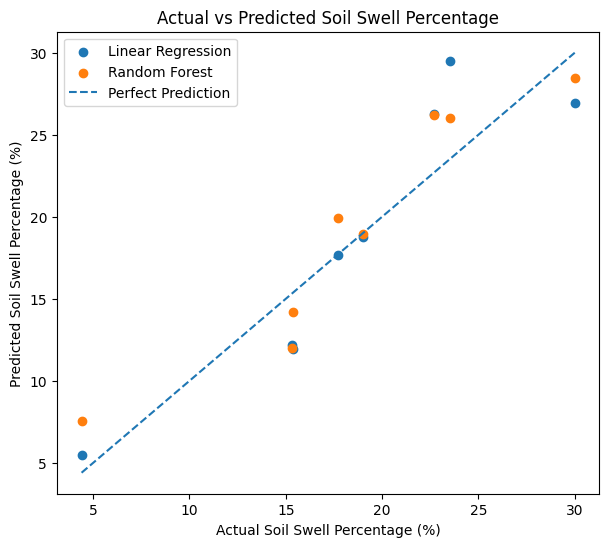

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_linear, label='Linear Regression')
plt.scatter(y_test, y_pred_rf, label='Random Forest')

# Perfect prediction line
min_value = min(y_test.min(), y_pred_linear.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_linear.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Soil Swell Percentage (%)')
plt.ylabel('Predicted Soil Swell Percentage (%)')
plt.title('Actual vs Predicted Soil Swell Percentage')
plt.legend()
plt.show()

## Comparison and Discussion

Two supervised regression models were developed to predict soil swell
percentage: Multiple Linear Regression and Random Forest Regression.

The models were evaluated using Mean Absolute Error (MAE), Mean Squared Error
(MSE), Root Mean Squared Error (RMSE), and the coefficient of determination
(R²).

The better-performing model is the model with lower MAE, MSE and RMSE and a
higher R² value. The model comparison shows which algorithm provides the more
accurate prediction of soil swelling for the selected soil properties.

Linear Regression provides a relatively simple baseline and assumes that the
relationship between the predictor variables and soil swelling can be
represented approximately by a linear relationship.

Random Forest Regression can model nonlinear relationships and interactions
between the soil properties. Therefore, if the Random Forest model produces
lower prediction errors and a higher R² value, this would indicate that the
relationship between the selected soil properties and swelling behaviour is
not adequately represented by a simple linear model.

The better-performing model can be selected as the preferred model
for predicting soil swell percentage within this dataset. However, its
predictions should be interpreted as a data-driven preliminary assessment and
not as a replacement for laboratory testing or detailed geotechnical
investigation.